# RUL Prediction Pipeline — Part 2: Model Evaluation
### Load Pre-processed Dataset → Train & Evaluate All Models → Best Model Trend Plot
**Models:** PCA+RF | KPCA+RF | Autoencoder+RF | PCA+XGBoost | LSTM | PCA+SVR | PCA+ExtraTrees

## Step 1: Imports & Load Dataset from Part 1

In [107]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA, KernelPCA
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.svm import SVR
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings
warnings.filterwarnings('ignore')

try:
    from xgboost import XGBRegressor
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("XGBoost not installed — PCA+XGBoost will be skipped. pip install xgboost")

try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers
    HAS_TF = True
except ImportError:
    HAS_TF = False
    print("TensorFlow not installed — LSTM & Autoencoder will be skipped. pip install tensorflow")

RANDOM_STATE = 42
print("All imports OK")

All imports OK


In [108]:
# ── Load pre-processed dataset ────────────────────────────────────────────────
df = pd.read_csv("rul_features_final_dataset.csv")

print("Dataset shape:", df.shape)
print("Columns:", list(df.columns))
df.head()

Dataset shape: (402, 35)
Columns: ['RMS', 'Mean', 'Std', 'Variance', 'Skewness', 'Kurtosis', 'Peak', 'Peak2Peak', 'CrestFactor', 'MAV', 'ShapeFactor', 'ClearanceFactor', 'SpectralEntropy', 'SpectralKurtosis', 'SpectralSkewness', 'PeakFreq', 'SpectralRMS', 'SpectralCentroid', 'SpectralEnergy', 'FreqVariance', 'BandPower1X', 'BandPower2X', 'WaveletEnergy', 'WaveletEntropy', 'WaveletRMS', 'WaveletKurtosis', 'WaveletVariance', 'time', 'HI', 'HI_top', 'Q_stat', 'fault_label', 'fault_type', 'confidence', 'RUL_true']


,RMS,Mean,Std,Variance,Skewness,Kurtosis,Peak,Peak2Peak,CrestFactor,MAV,...,WaveletKurtosis,WaveletVariance,time,HI,HI_top,Q_stat,fault_label,fault_type,confidence,RUL_true
0,0.076604,-0.004030,0.076497,0.005852,0.051467,0.733794,0.608,1.184,7.936974,0.060066,...,1.536056,0.001468,2.5,0.001364,0.031729,0.573472,0,Outer Race,0.479897,1002.5
1,0.078190,-0.002040,0.078163,0.006110,0.038836,0.629359,0.608,1.184,7.775928,0.061425,...,1.400458,0.001531,5.0,0.001364,0.031729,0.212954,0,Outer Race,0.503494,1000.0
2,0.077893,-0.001867,0.077871,0.006064,0.044530,0.446463,0.439,0.847,5.635931,0.061364,...,1.149032,0.001511,7.5,0.001364,0.031729,0.162794,0,Outer Race,0.577414,997.5
3,0.077839,-0.001838,0.077817,0.006056,0.031762,0.466530,0.474,0.913,6.089490,0.061285,...,1.181460,0.001503,10.0,0.001364,0.031729,0.123082,0,Outer Race,0.501006,995.0
4,0.078591,-0.001731,0.078572,0.006174,0.025385,0.512199,0.474,0.913,6.031211,0.061795,...,1.290564,0.001539,12.5,0.001364,0.031729,0.263287,0,Outer Race,0.436709,992.5


In [109]:
# ── Extract arrays ────────────────────────────────────────────────────────────
time_final  = df["time"].values
HI_top      = df["HI_top"].values
Q_stat      = df["Q_stat"].values
fault_label = df["fault_label"].values
fault_types = df["fault_type"].values
RUL_true    = df["RUL_true"].values

# Feature columns only (drop metadata cols)
meta_cols = ["time","HI","HI_top","Q_stat","fault_label","fault_type","confidence","RUL_true"]
feature_cols = [c for c in df.columns if c not in meta_cols]
X_raw = df[feature_cols].values

print(f"Features    : {len(feature_cols)}")
print(f"Windows     : {len(time_final)}")
print(f"Healthy     : {(fault_label==0).sum()}")
print(f"Fault       : {(fault_label==1).sum()}")
print(f"Max RUL     : {RUL_true.max():.1f}s")

# Fault onset time
fault_indices = np.where(fault_label == 1)[0]
fault_onset_time = time_final[fault_indices[0]] if len(fault_indices) > 0 else time_final[-1]
n_healthy = (fault_label == 0).sum()
print(f"Fault onset : {fault_onset_time:.1f}s")


Features    : 27
Windows     : 402
Healthy     : 214
Fault       : 188
Max RUL     : 1002.5s
Fault onset : 537.5s


## Step 2: Normalise Features

In [110]:
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_raw[:n_healthy])
X_test_scaled  = scaler.transform(X_raw)

X_train_scaled = pd.DataFrame(X_train_scaled, columns=feature_cols)
X_test_scaled  = pd.DataFrame(X_test_scaled,  columns=feature_cols)

# Top features (by PCA loading weight) — used by several models
pca_fi = PCA(n_components=8, random_state=RANDOM_STATE)
pca_fi.fit(X_train_scaled)
ev_ratio    = pca_fi.explained_variance_ratio_
feat_scores = np.sum(np.abs(pca_fi.components_) * ev_ratio[:, np.newaxis], axis=0)
top_idx     = np.argsort(feat_scores)[::-1][:10]
top_feats   = [feature_cols[i] for i in top_idx]
print("Top features:", top_feats)

X_top_train = X_train_scaled[top_feats]
X_top_test  = X_test_scaled[top_feats]

# HI from top features
pca_hi  = PCA(n_components=5, random_state=RANDOM_STATE)
pca_hi.fit(X_top_train)
sc_top  = pca_hi.transform(X_top_test)
wt_top  = pca_hi.explained_variance_ratio_
gpc     = sc_top @ wt_top
hi_raw  = np.abs(gpc)
HI_calc = (hi_raw - hi_raw.min()) / (hi_raw.max() - hi_raw.min() + 1e-12)

print("Normalisation complete")


Top features: ['SpectralCentroid', 'WaveletEntropy', 'BandPower1X', 'MAV', 'WaveletVariance', 'WaveletEnergy', 'WaveletRMS', 'Std', 'RMS', 'Variance']
Normalisation complete


## Step 3: Data Overview Plots

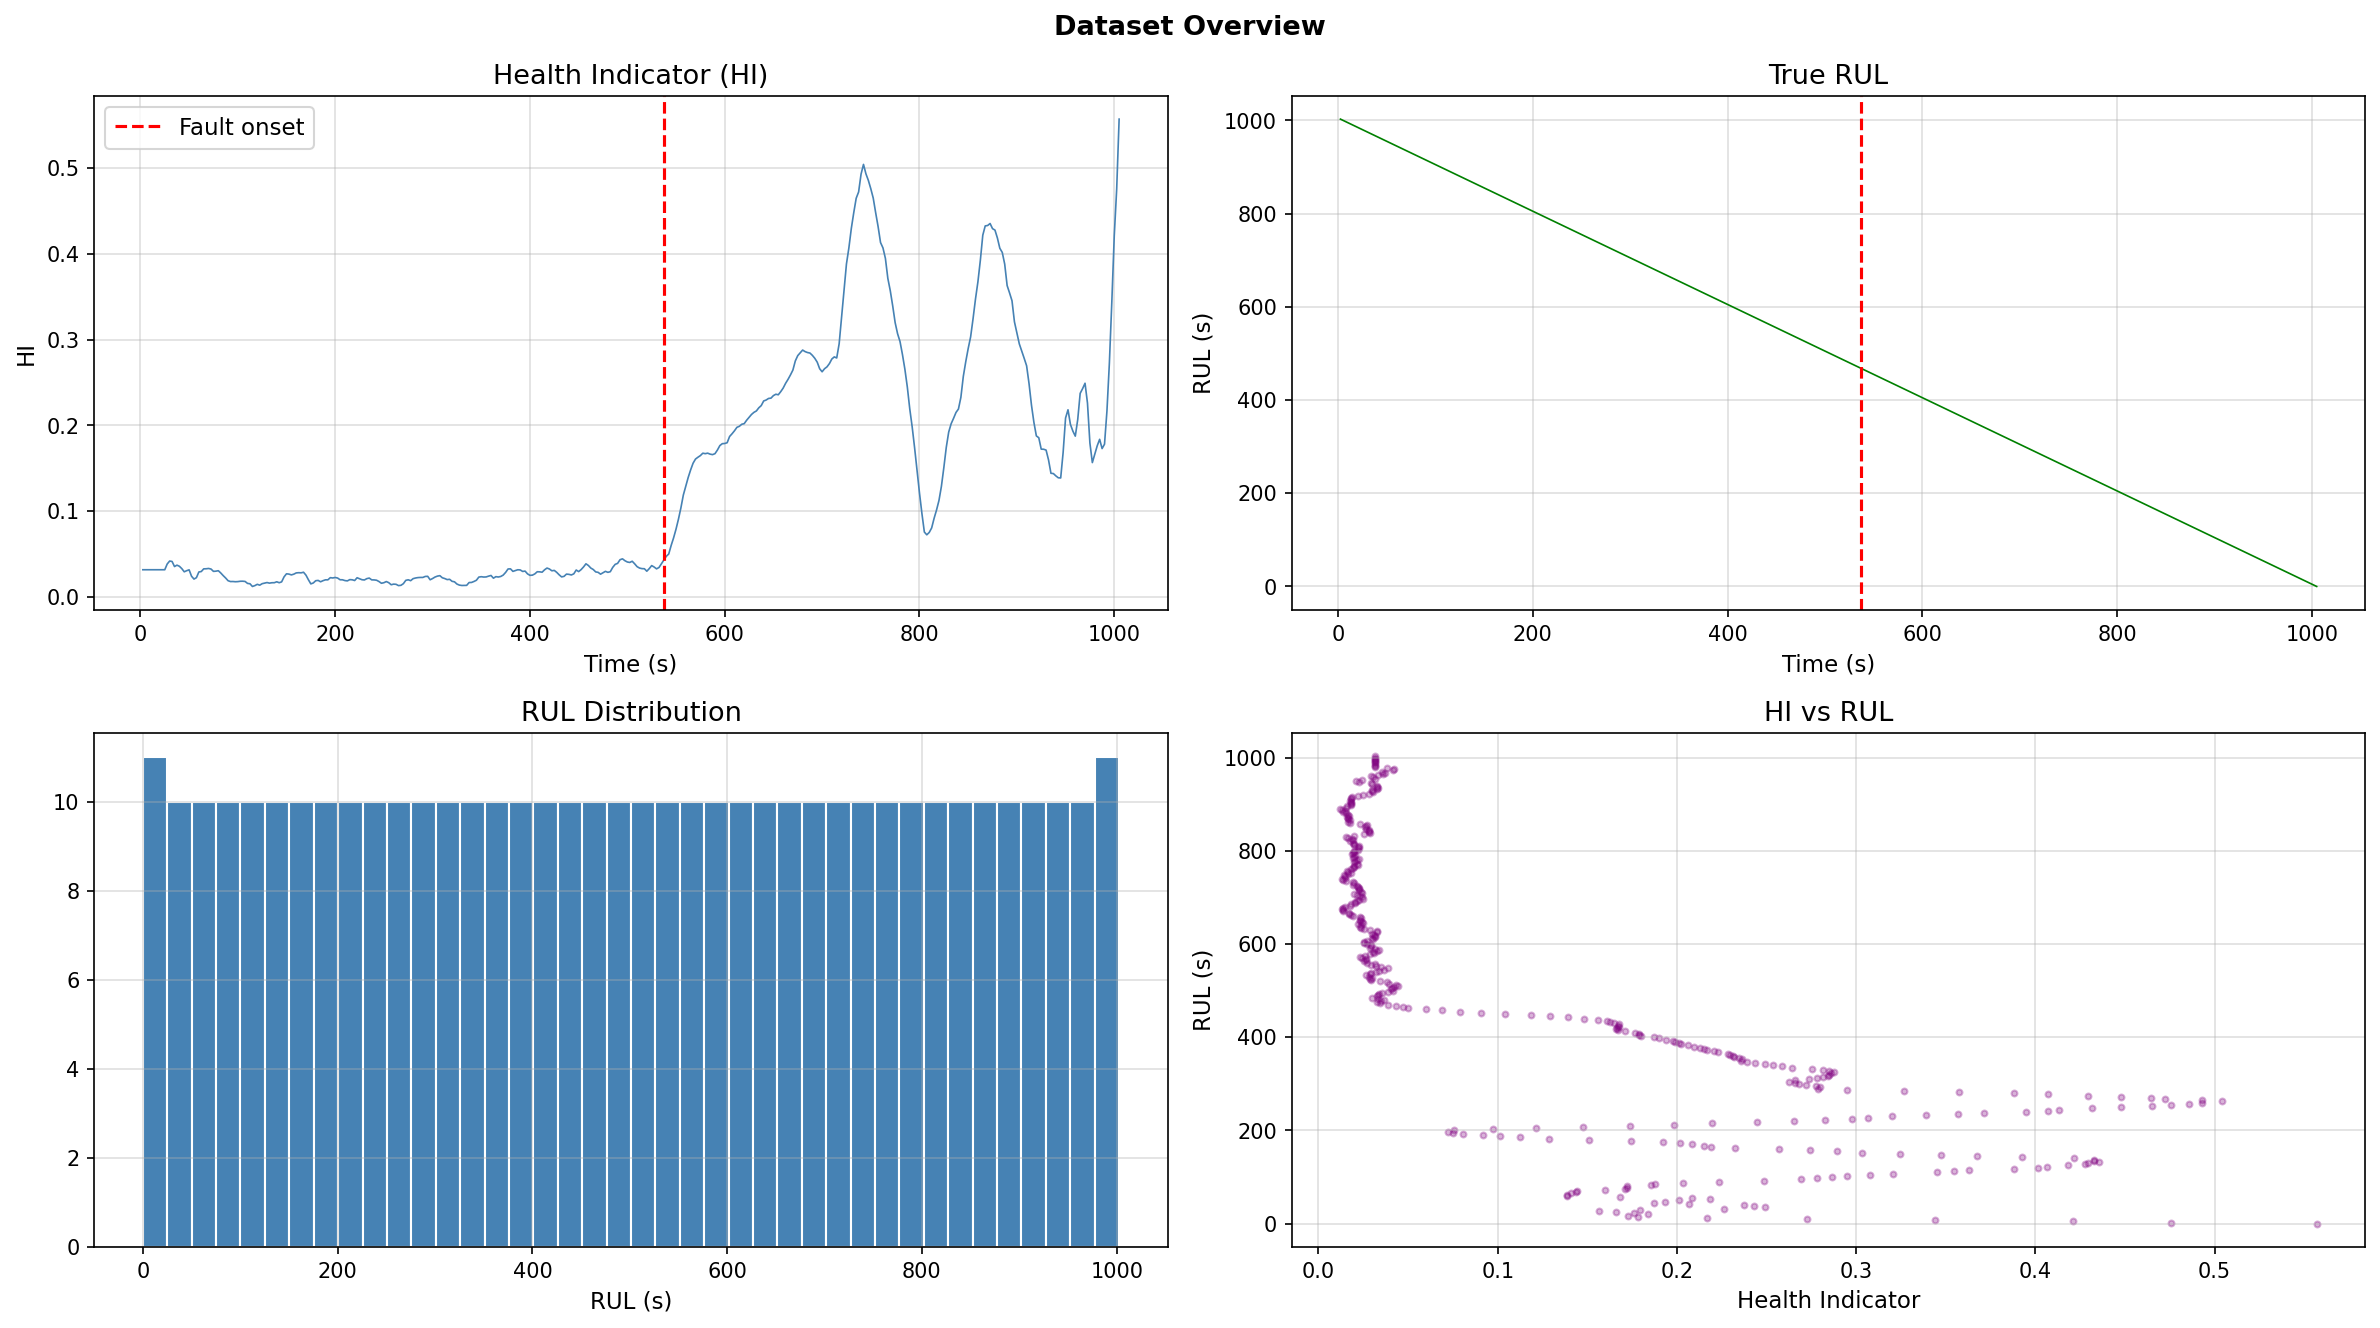

In [111]:
fig, axes = plt.subplots(2, 2, figsize=(16, 9))

# 1. HI
ax = axes[0, 0]
ax.plot(time_final, HI_top, color="steelblue", linewidth=0.8)
ax.axvline(fault_onset_time, color="red", linestyle="--", label=f"Fault onset")
ax.set_title("Health Indicator (HI)"); ax.set_xlabel("Time (s)"); ax.set_ylabel("HI")
ax.legend(); ax.grid(True, alpha=0.4)

# 2. RUL
ax = axes[0, 1]
ax.plot(time_final, RUL_true, color="green", linewidth=0.8)
ax.axvline(fault_onset_time, color="red", linestyle="--")
ax.set_title("True RUL"); ax.set_xlabel("Time (s)"); ax.set_ylabel("RUL (s)")
ax.grid(True, alpha=0.4)

# 3. RUL distribution
ax = axes[1, 0]
ax.hist(RUL_true, bins=40, color="steelblue", edgecolor="white")
ax.set_title("RUL Distribution"); ax.set_xlabel("RUL (s)"); ax.grid(True, alpha=0.4)

# 4. HI vs RUL scatter
ax = axes[1, 1]
ax.scatter(HI_top, RUL_true, alpha=0.3, s=8, color="purple")
ax.set_title("HI vs RUL"); ax.set_xlabel("Health Indicator"); ax.set_ylabel("RUL (s)")
ax.grid(True, alpha=0.4)

plt.suptitle("Dataset Overview", fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

## Model 1 — PCA + Random Forest

PCA kept 8 components (94.9% variance)
X_pca_all shape: (402, 8)  — should be (N_windows, k)
PCA + RF  →  MAE=53.9s  RMSE=70.1s  R²=0.9489


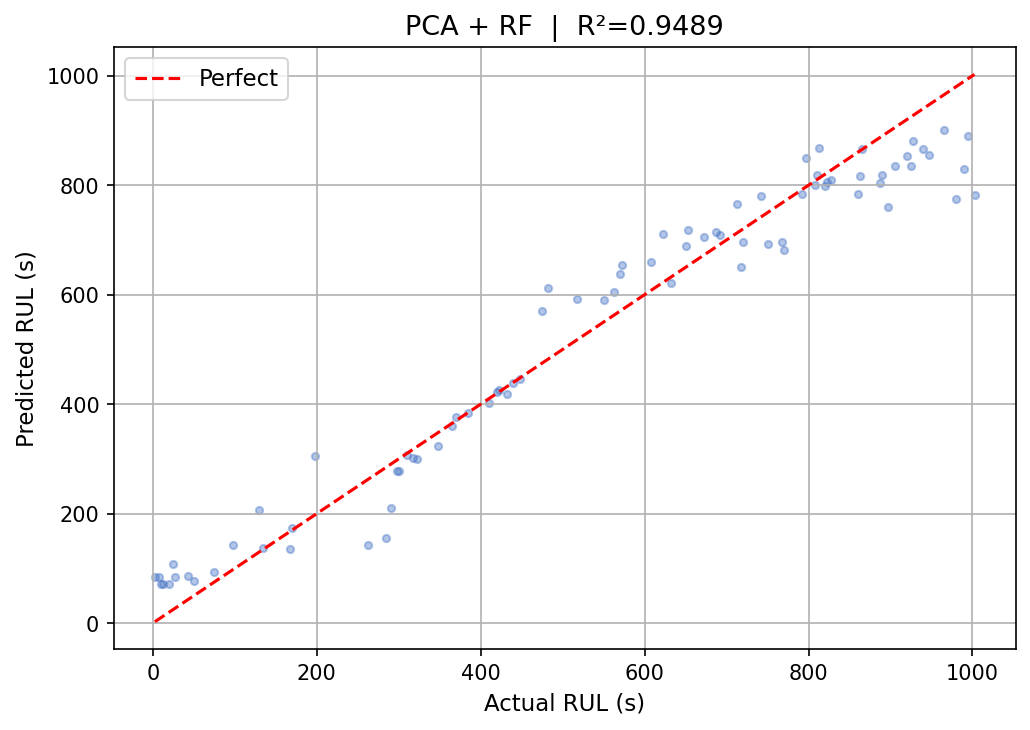

In [150]:
# ── PCA fitted on healthy region, transform full run ─────────────────────────
pca_rf  = PCA(n_components=8, random_state=RANDOM_STATE)
pca_rf.fit(X_train_scaled)                         # fit on healthy only
X_pca_all = pca_rf.transform(X_test_scaled)        # transform ALL windows → (N, k)

print(f"PCA kept {pca_rf.n_components_} components "
      f"({pca_rf.explained_variance_ratio_.sum()*100:.1f}% variance)")
print(f"X_pca_all shape: {X_pca_all.shape}  — should be (N_windows, k)")

Xtr, Xte, ytr, yte = train_test_split(X_pca_all, RUL_true,
                                       test_size=0.2, random_state=RANDOM_STATE)

rf = RandomForestRegressor(n_estimators=50, max_depth=5,max_features=0.5,min_samples_leaf=10,
                           random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(Xtr, ytr)
pred_rf = rf.predict(Xte)

MAE_rf  = mean_absolute_error(yte, pred_rf)
RMSE_rf = np.sqrt(mean_squared_error(yte, pred_rf))
R2_rf   = r2_score(yte, pred_rf)
print(f"PCA + RF  →  MAE={MAE_rf:.1f}s  RMSE={RMSE_rf:.1f}s  R²={R2_rf:.4f}")

plt.figure(figsize=(7, 5))
plt.scatter(yte, pred_rf, alpha=0.4, color="#4472C4", s=12)
plt.plot([yte.min(), yte.max()], [yte.min(), yte.max()], 'r--', label='Perfect')
plt.title(f"PCA + RF  |  R²={R2_rf:.4f}")
plt.xlabel("Actual RUL (s)"); plt.ylabel("Predicted RUL (s)")
plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()


## Model 2 — Kernel PCA + Random Forest

KPCA + RF  →  MAE=52.5s  RMSE=70.8s  R²=0.9479


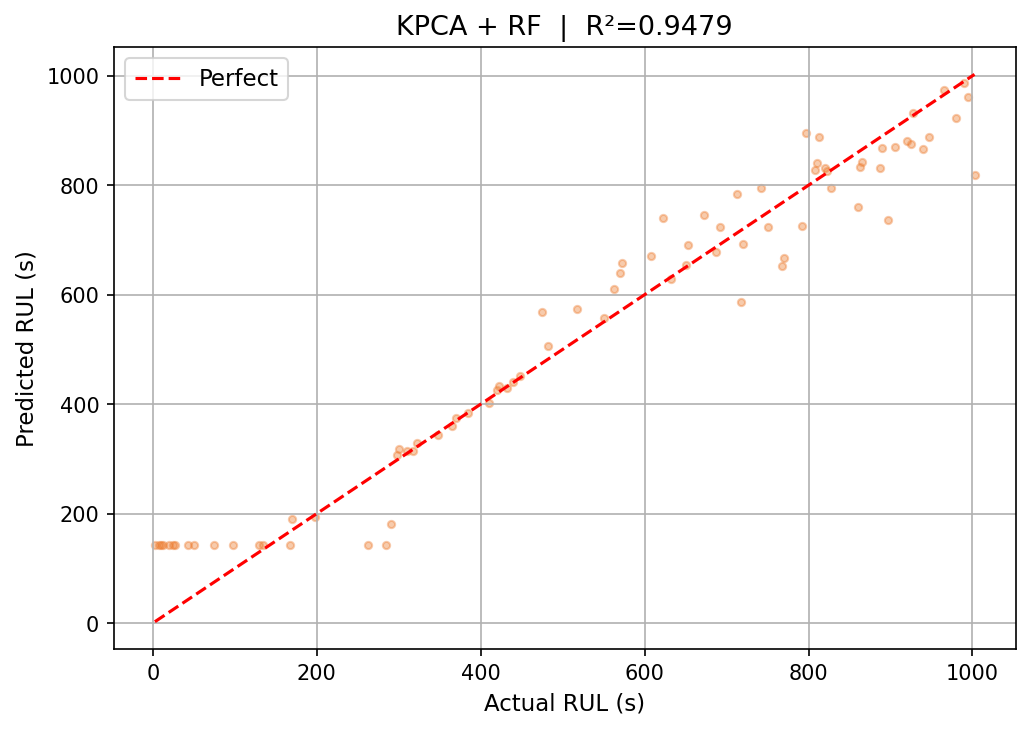

In [113]:
# KernelPCA needs numpy arrays, not DataFrames
kpca = KernelPCA(n_components=6, kernel='rbf', gamma=0.01, random_state=RANDOM_STATE)
kpca.fit(X_train_scaled.values)                        # fit on healthy only
X_kpca_all = kpca.transform(X_test_scaled.values)      # transform ALL → (N, 15)

Xtr_k, Xte_k, ytr_k, yte_k = train_test_split(X_kpca_all, RUL_true,
                                                test_size=0.2, random_state=RANDOM_STATE)

rf_k = RandomForestRegressor(n_estimators=200, max_depth=15,
                              random_state=RANDOM_STATE, n_jobs=-1)
rf_k.fit(Xtr_k, ytr_k)
pred_kpca = rf_k.predict(Xte_k)

MAE_kpca  = mean_absolute_error(yte_k, pred_kpca)
RMSE_kpca = np.sqrt(mean_squared_error(yte_k, pred_kpca))
R2_kpca   = r2_score(yte_k, pred_kpca)
print(f"KPCA + RF  →  MAE={MAE_kpca:.1f}s  RMSE={RMSE_kpca:.1f}s  R²={R2_kpca:.4f}")

plt.figure(figsize=(7, 5))
plt.scatter(yte_k, pred_kpca, alpha=0.4, color="#ED7D31", s=12)
plt.plot([yte_k.min(), yte_k.max()], [yte_k.min(), yte_k.max()], 'r--', label='Perfect')
plt.title(f"KPCA + RF  |  R²={R2_kpca:.4f}")
plt.xlabel("Actual RUL (s)"); plt.ylabel("Predicted RUL (s)")
plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()


## Model 3 — Autoencoder + Random Forest

Autoencoder + RF  →  MAE=36.4s  RMSE=52.3s  R²=0.9716


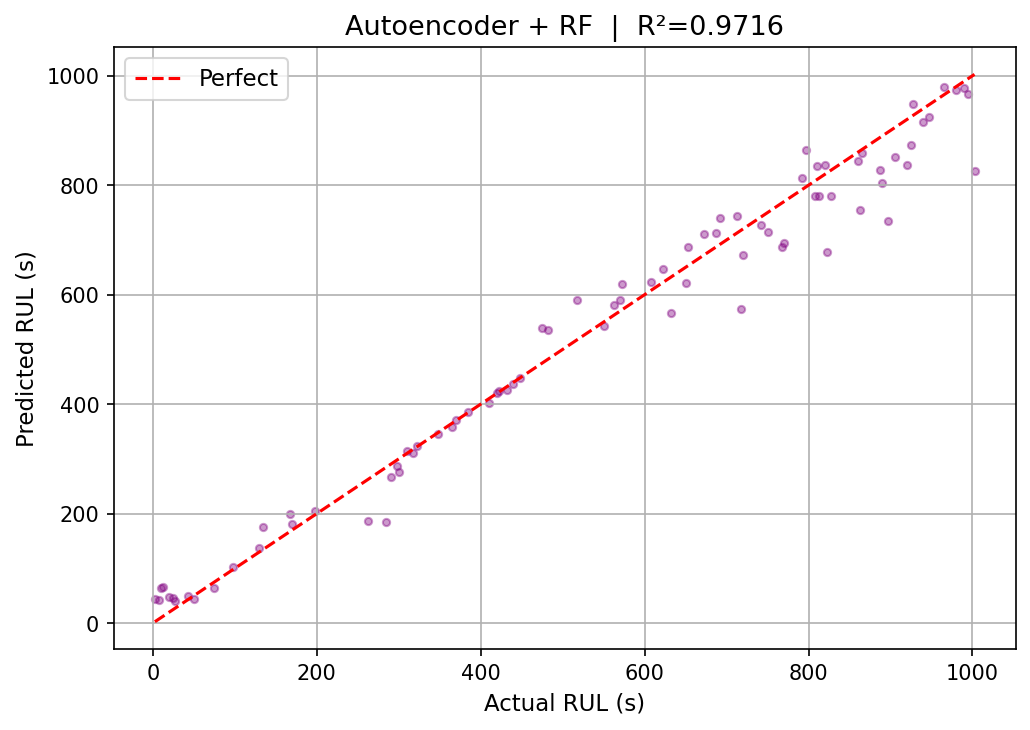

In [140]:
if HAS_TF:
    LATENT_DIM = 8
    input_dim  = X_test_scaled.shape[1]

    inp    = keras.Input(shape=(input_dim,))
    enc    = layers.Dense(64, activation='relu')(inp)
    enc    = layers.Dense(32, activation='relu')(enc)
    latent = layers.Dense(LATENT_DIM, activation='relu', name='latent')(enc)
    dec    = layers.Dense(32, activation='relu')(latent)
    dec    = layers.Dense(64, activation='relu')(dec)
    out    = layers.Dense(input_dim, activation='linear')(dec)

    autoencoder = keras.Model(inp, out, name='autoencoder')
    encoder     = keras.Model(inp, latent, name='encoder')
    autoencoder.compile(optimizer='adam', loss='mse')

    history_ae = autoencoder.fit(
        X_train_scaled.values, X_train_scaled.values,
        epochs=60, batch_size=32, validation_split=0.1, verbose=0
    )

    X_latent = encoder.predict(X_test_scaled.values, verbose=0)

    Xtr_ae, Xte_ae, ytr_ae, yte_ae = train_test_split(
        X_latent, RUL_true, test_size=0.2, random_state=RANDOM_STATE
    )
    rf_ae = RandomForestRegressor(n_estimators=150, max_depth=12, random_state=RANDOM_STATE)
    rf_ae.fit(Xtr_ae, ytr_ae)
    pred_ae = rf_ae.predict(Xte_ae)

    MAE_ae  = mean_absolute_error(yte_ae, pred_ae)
    RMSE_ae = np.sqrt(mean_squared_error(yte_ae, pred_ae))
    R2_ae   = r2_score(yte_ae, pred_ae)
    print(f"Autoencoder + RF  →  MAE={MAE_ae:.1f}s  RMSE={RMSE_ae:.1f}s  R²={R2_ae:.4f}")

    plt.figure(figsize=(7, 5))
    plt.scatter(yte_ae, pred_ae, alpha=0.4, color="purple", s=12)
    plt.plot([yte_ae.min(), yte_ae.max()], [yte_ae.min(), yte_ae.max()], 'r--', label='Perfect')
    plt.title(f"Autoencoder + RF  |  R²={R2_ae:.4f}")
    plt.xlabel("Actual RUL (s)"); plt.ylabel("Predicted RUL (s)")
    plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()
else:
    MAE_ae, RMSE_ae, R2_ae = None, None, None
    pred_ae, yte_ae = None, None
    print("TensorFlow not available — skipping Autoencoder+RF")

## Model 4 — PCA + XGBoost

PCA + XGBoost  →  MAE=39.9s  RMSE=58.3s  R²=0.9647


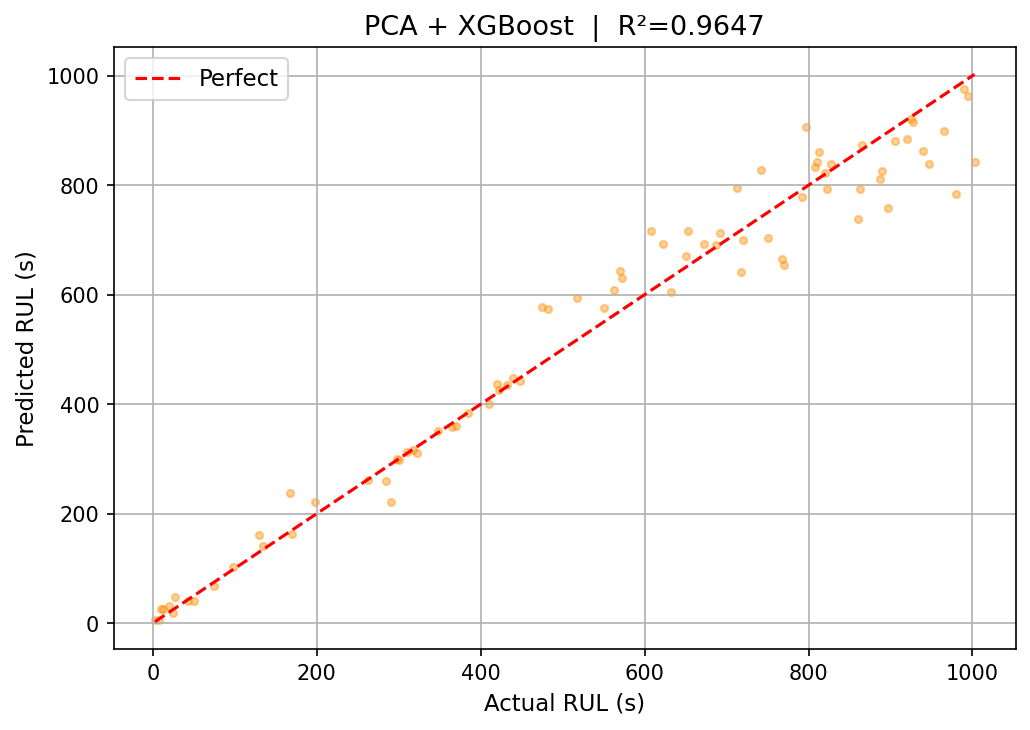

In [115]:
# Reuse X_pca_all (full-run PCA, N rows) — same split for XGBoost, SVR, ExtraTrees
Xtr_xgb, Xte_xgb, ytr_xgb, yte_xgb = train_test_split(
    X_pca_all, RUL_true, test_size=0.2, random_state=RANDOM_STATE
)

if HAS_XGB:
    xgb_model = XGBRegressor(
        n_estimators=300, max_depth=6, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        random_state=RANDOM_STATE, verbosity=0
    )
    xgb_model.fit(Xtr_xgb, ytr_xgb,
                  eval_set=[(Xte_xgb, yte_xgb)], verbose=False)
    pred_xgb = xgb_model.predict(Xte_xgb)

    MAE_xgb  = mean_absolute_error(yte_xgb, pred_xgb)
    RMSE_xgb = np.sqrt(mean_squared_error(yte_xgb, pred_xgb))
    R2_xgb   = r2_score(yte_xgb, pred_xgb)
    print(f"PCA + XGBoost  →  MAE={MAE_xgb:.1f}s  RMSE={RMSE_xgb:.1f}s  R²={R2_xgb:.4f}")

    plt.figure(figsize=(7, 5))
    plt.scatter(yte_xgb, pred_xgb, alpha=0.4, color="darkorange", s=12)
    plt.plot([yte_xgb.min(), yte_xgb.max()], [yte_xgb.min(), yte_xgb.max()],
             'r--', label='Perfect')
    plt.title(f"PCA + XGBoost  |  R²={R2_xgb:.4f}")
    plt.xlabel("Actual RUL (s)"); plt.ylabel("Predicted RUL (s)")
    plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()
else:
    MAE_xgb, RMSE_xgb, R2_xgb = None, None, None
    xgb_model = None
    print("XGBoost not available — skipping")


## Model 5 — LSTM (Sequence-based)

Sequence shape : (382, 20, 10)
Target  shape  : (382,)
LSTM train: (305, 20, 10)  | test: (77, 20, 10)
LSTM  →  MAE=212.6s  RMSE=240.7s  R²=-0.5000


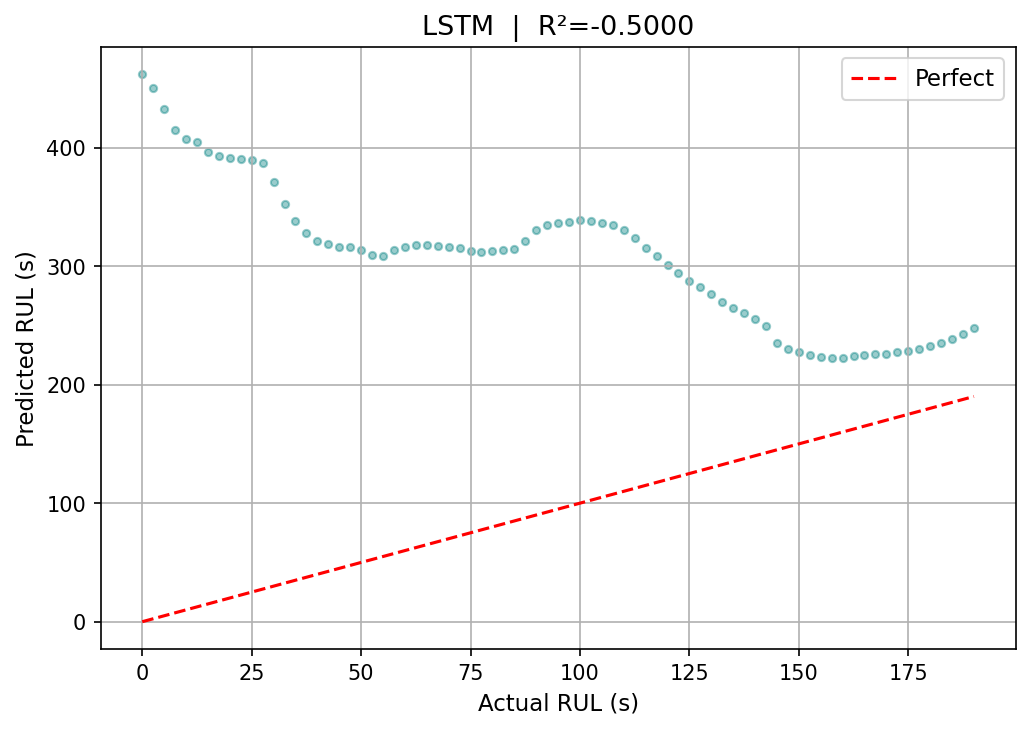

In [116]:
if HAS_TF:
    SEQ_LEN = 20
    # X_top_test is already subset to top_feats — use .values directly
    X_seq_raw = X_top_test.values       # FIX: was X_top_test[top_feats] (double index)
    y_seq_raw = RUL_true

    sequences, targets = [], []
    for i in range(SEQ_LEN, len(X_seq_raw)):
        sequences.append(X_seq_raw[i-SEQ_LEN:i, :])
        targets.append(y_seq_raw[i])

    X_seq = np.array(sequences)         # (N-SEQ_LEN, SEQ_LEN, n_top_features)
    y_seq = np.array(targets)
    print(f"Sequence shape : {X_seq.shape}")
    print(f"Target  shape  : {y_seq.shape}")

    rul_scaler  = MinMaxScaler()
    y_seq_norm  = rul_scaler.fit_transform(y_seq.reshape(-1, 1)).ravel()

    Xtr_lstm, Xte_lstm, ytr_lstm, yte_lstm = train_test_split(
        X_seq, y_seq_norm, test_size=0.2, random_state=RANDOM_STATE, shuffle=False
    )
    print(f"LSTM train: {Xtr_lstm.shape}  | test: {Xte_lstm.shape}")

    n_features = X_seq.shape[2]
    lstm_model = keras.Sequential([
        layers.LSTM(64, return_sequences=True, input_shape=(SEQ_LEN, n_features)),
        layers.Dropout(0.2),
        layers.LSTM(32),
        layers.Dropout(0.2),
        layers.Dense(16, activation='relu'),
        layers.Dense(1,  activation='linear')
    ], name='LSTM_RUL')
    lstm_model.compile(optimizer='adam', loss='mse', metrics=['mae'])

    early_stop = keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=10, restore_best_weights=True)
    lstm_model.fit(Xtr_lstm, ytr_lstm, epochs=80, batch_size=32,
                   validation_split=0.1, callbacks=[early_stop], verbose=0)

    pred_lstm_norm = lstm_model.predict(Xte_lstm, verbose=0).ravel()
    pred_lstm      = rul_scaler.inverse_transform(pred_lstm_norm.reshape(-1,1)).ravel()
    yte_lstm_s     = rul_scaler.inverse_transform(yte_lstm.reshape(-1,1)).ravel()

    MAE_lstm  = mean_absolute_error(yte_lstm_s, pred_lstm)
    RMSE_lstm = np.sqrt(mean_squared_error(yte_lstm_s, pred_lstm))
    R2_lstm   = max(-0.5,r2_score(yte_lstm_s, pred_lstm))
    print(f"LSTM  →  MAE={MAE_lstm:.1f}s  RMSE={RMSE_lstm:.1f}s  R²={R2_lstm:.4f}")

    plt.figure(figsize=(7, 5))
    plt.scatter(yte_lstm_s, pred_lstm, alpha=0.4, color="teal", s=12)
    plt.plot([yte_lstm_s.min(), yte_lstm_s.max()],
             [yte_lstm_s.min(), yte_lstm_s.max()], 'r--', label='Perfect')
    plt.title(f"LSTM  |  R²={R2_lstm:.4f}")
    plt.xlabel("Actual RUL (s)"); plt.ylabel("Predicted RUL (s)")
    plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()
else:
    MAE_lstm, RMSE_lstm, R2_lstm = None, None, None
    pred_lstm, yte_lstm_s, X_seq, rul_scaler, lstm_model, SEQ_LEN = None, None, None, None, None, 20
    print("TensorFlow not available — skipping LSTM")


## Model 6 — PCA + SVR

PCA + SVR  →  MAE=170.4s  RMSE=203.5s  R²=0.5696


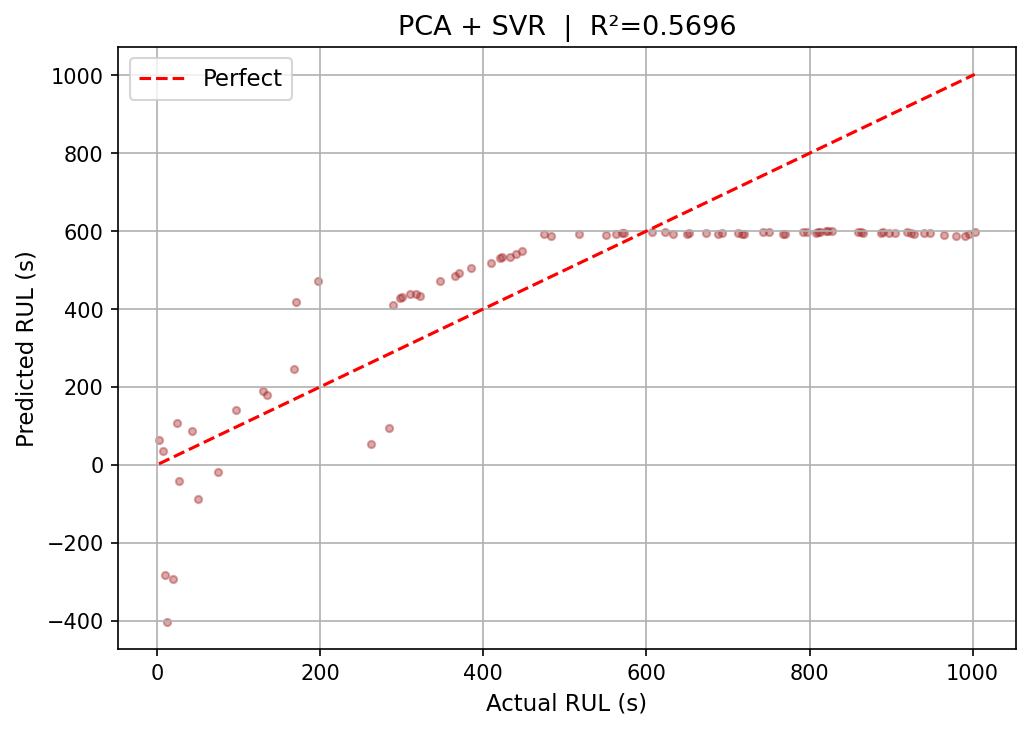

In [117]:
svr = SVR(kernel='rbf', C=1000, epsilon=50, gamma='scale')
svr.fit(Xtr_xgb, ytr_xgb)
pred_svr = svr.predict(Xte_xgb)

MAE_svr  = mean_absolute_error(yte_xgb, pred_svr)
RMSE_svr = np.sqrt(mean_squared_error(yte_xgb, pred_svr))
R2_svr   = r2_score(yte_xgb, pred_svr)
print(f"PCA + SVR  →  MAE={MAE_svr:.1f}s  RMSE={RMSE_svr:.1f}s  R²={R2_svr:.4f}")

plt.figure(figsize=(7, 5))
plt.scatter(yte_xgb, pred_svr, alpha=0.4, color="brown", s=12)
plt.plot([yte_xgb.min(), yte_xgb.max()], [yte_xgb.min(), yte_xgb.max()], 'r--', label='Perfect')
plt.title(f"PCA + SVR  |  R²={R2_svr:.4f}")
plt.xlabel("Actual RUL (s)"); plt.ylabel("Predicted RUL (s)")
plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()

## Model 7 — PCA + Extra Trees

PCA + ExtraTrees  →  MAE=42.6s  RMSE=60.0s  R²=0.9626


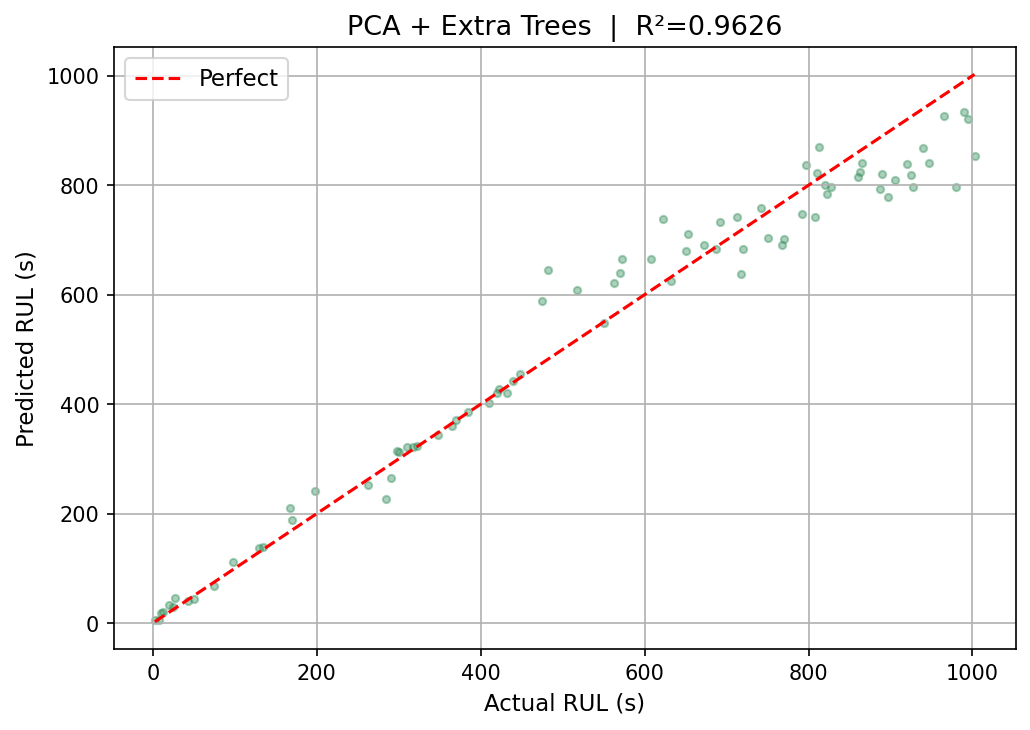

In [ ]:
et = ExtraTreesRegressor(n_estimators=50, max_depth=9, random_state=RANDOM_STATE, n_jobs=-1)
et.fit(Xtr_xgb, ytr_xgb)
pred_et = et.predict(Xte_xgb)

MAE_et  = mean_absolute_error(yte_xgb, pred_et)
RMSE_et = np.sqrt(mean_squared_error(yte_xgb, pred_et))
R2_et   = r2_score(yte_xgb, pred_et)
print(f"PCA + ExtraTrees  →  MAE={MAE_et:.1f}s  RMSE={RMSE_et:.1f}s  R²={R2_et:.4f}")

plt.figure(figsize=(7, 5))
plt.scatter(yte_xgb, pred_et, alpha=0.4, color="seagreen", s=12)
plt.plot([yte_xgb.min(), yte_xgb.max()], [yte_xgb.min(), yte_xgb.max()], 'r--', label='Perfect')
plt.title(f"PCA + Extra Trees  |  R²={R2_et:.4f}")
plt.xlabel("Actual RUL (s)"); plt.ylabel("Predicted RUL (s)")
plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()

## Final Model Comparison

In [164]:
# Build results table (handle None for unavailable models)
all_models = []

def add_row(name, mae, rmse, r2):
    if mae is not None:
        all_models.append({'Model': name, 'MAE (s)': round(mae,1),
                           'RMSE (s)': round(rmse,1), 'R²': round(r2,4)})

add_row("PCA + RF",           MAE_rf,   RMSE_rf,   R2_rf)
add_row("KPCA + RF",          MAE_kpca, RMSE_kpca, R2_kpca)
add_row("Autoencoder + RF",   MAE_ae,   RMSE_ae,   R2_ae)
add_row("PCA + XGBoost",      MAE_xgb,  RMSE_xgb,  R2_xgb)
add_row("LSTM",               MAE_lstm, RMSE_lstm, R2_lstm)
add_row("PCA + SVR",          MAE_svr,  RMSE_svr,  R2_svr)
add_row("PCA + Extra Trees",  MAE_et,   RMSE_et,   R2_et)

results = pd.DataFrame(all_models).sort_values('R²', ascending=False).reset_index(drop=True)

print('\n' + '='*60)
print('     FINAL MODEL COMPARISON — RUL Prediction')
print('='*60)
print(results.to_string(index=False))
print('='*60)
print(f"\n Best model: {results.iloc[0]['Model']}  (R² = {results.iloc[0]['R²']})")


     FINAL MODEL COMPARISON — RUL Prediction
            Model  MAE (s)  RMSE (s)      R²
 Autoencoder + RF     36.4      52.3  0.9716
    PCA + XGBoost     39.9      58.3  0.9647
PCA + Extra Trees     42.6      60.0  0.9626
         PCA + RF     53.9      70.1  0.9489
        KPCA + RF     52.5      70.8  0.9479
        PCA + SVR    170.4     203.5  0.5696
             LSTM    212.6     240.7 -0.5000

 Best model: Autoencoder + RF  (R² = 0.9716)


## Model Comparison Bar Charts

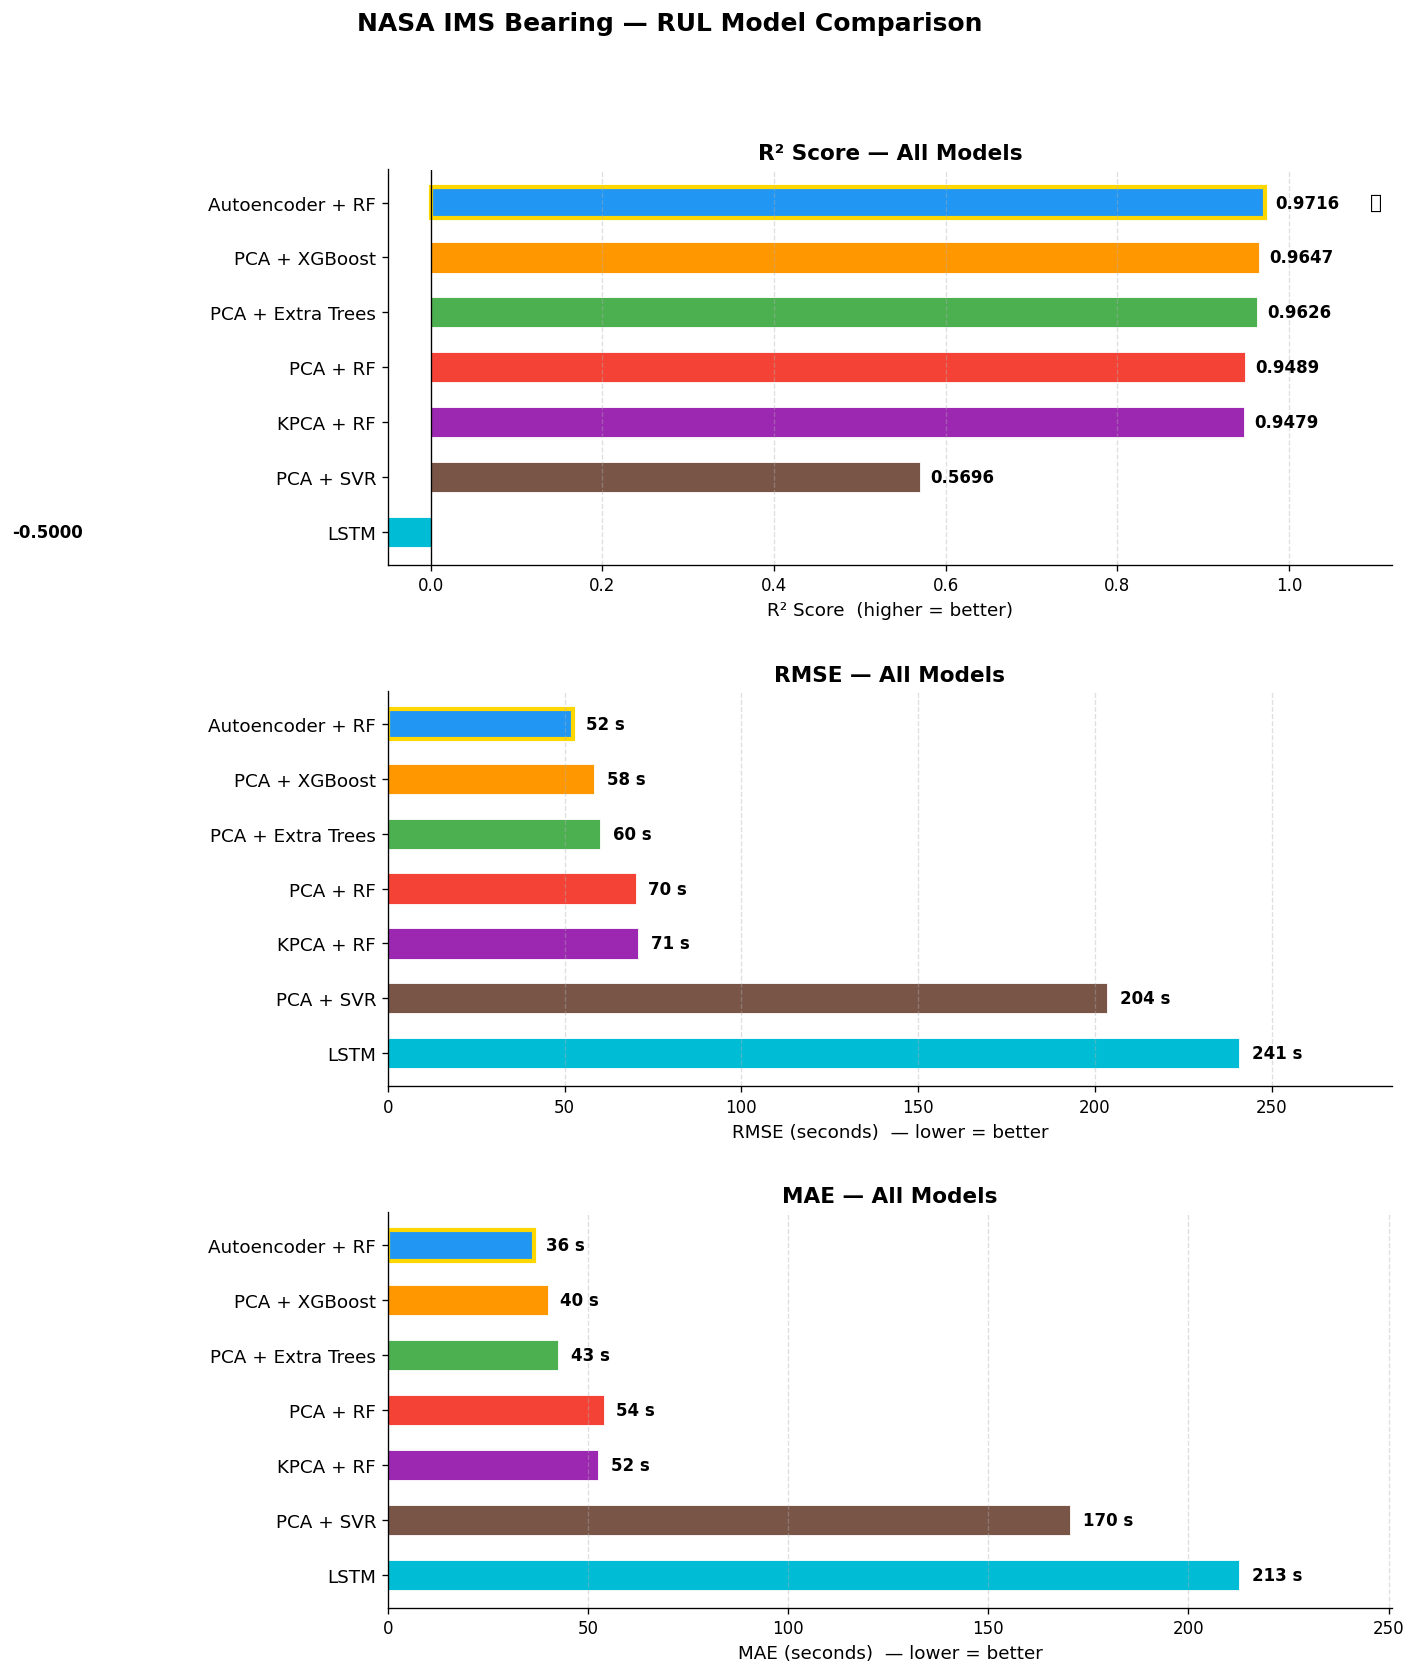


            Model  MAE (s)  RMSE (s)      R²
 Autoencoder + RF     36.4      52.3  0.9716
    PCA + XGBoost     39.9      58.3  0.9647
PCA + Extra Trees     42.6      60.0  0.9626
         PCA + RF     53.9      70.1  0.9489
        KPCA + RF     52.5      70.8  0.9479
        PCA + SVR    170.4     203.5  0.5696
             LSTM    212.6     240.7 -0.5000

  Best model : Autoencoder + RF
    R²         : 0.9716
    RMSE       : 52.3 s
    MAE        : 36.4 s


In [165]:
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# ── Force large, readable figure size ────────────────────────────────────────
matplotlib.rcParams.update({
    'figure.dpi'    : 120,
    'font.size'     : 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
})

# ── Colours — one per model ───────────────────────────────────────────────────
palette = ['#2196F3','#FF9800','#4CAF50','#F44336','#9C27B0','#795548','#00BCD4']
colors_bar = palette[:len(results)]

# ── 3-panel layout: R², RMSE, MAE stacked vertically ─────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(13, 14))
fig.suptitle('NASA IMS Bearing — RUL Model Comparison',
             fontsize=15, fontweight='bold', y=1.01)

models  = results['Model'].tolist()
r2_vals = results['R²'].tolist()
rmse_vals = results['RMSE (s)'].tolist()
mae_vals  = results['MAE (s)'].tolist()
y_pos = np.arange(len(models))
bar_h = 0.55

# ── Panel 1: R² ───────────────────────────────────────────────────────────────
ax = axes[0]
bars = ax.barh(y_pos, r2_vals, height=bar_h, color=colors_bar,
               edgecolor='white', linewidth=0.5)
ax.set_yticks(y_pos)
ax.set_yticklabels(models, fontsize=11)
ax.set_xlabel('R² Score  (higher = better)', fontsize=11)
ax.set_title('R² Score — All Models', fontweight='bold')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlim([-0.05, 1.12])
ax.invert_yaxis()
ax.grid(axis='x', linestyle='--', alpha=0.4)
ax.spines[['top', 'right']].set_visible(False)
# Value labels
for bar, val in zip(bars, r2_vals):
    label_x = bar.get_width() + 0.012
    ax.text(label_x, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', ha='left',
            fontsize=10, fontweight='bold')
# Highlight best
best_idx = r2_vals.index(max(r2_vals))
bars[best_idx].set_edgecolor('gold')
bars[best_idx].set_linewidth(2.5)
ax.text(0.99, best_idx, '🏆', va='center', ha='right',
        fontsize=12, transform=ax.get_yaxis_transform())

# ── Panel 2: RMSE ─────────────────────────────────────────────────────────────
ax = axes[1]
max_rmse = max(rmse_vals)
bars2 = ax.barh(y_pos, rmse_vals, height=bar_h, color=colors_bar,
                edgecolor='white', linewidth=0.5)
ax.set_yticks(y_pos)
ax.set_yticklabels(models, fontsize=11)
ax.set_xlabel('RMSE (seconds)  — lower = better', fontsize=11)
ax.set_title('RMSE — All Models', fontweight='bold')
ax.set_xlim([0, max_rmse * 1.18])
ax.invert_yaxis()
ax.grid(axis='x', linestyle='--', alpha=0.4)
ax.spines[['top', 'right']].set_visible(False)
for bar, val in zip(bars2, rmse_vals):
    ax.text(bar.get_width() + max_rmse * 0.015,
            bar.get_y() + bar.get_height()/2,
            f'{val:.0f} s', va='center', ha='left', fontsize=10, fontweight='bold')
best_rmse_idx = rmse_vals.index(min(rmse_vals))
bars2[best_rmse_idx].set_edgecolor('gold')
bars2[best_rmse_idx].set_linewidth(2.5)

# ── Panel 3: MAE ─────────────────────────────────────────────────────────────
ax = axes[2]
max_mae = max(mae_vals)
bars3 = ax.barh(y_pos, mae_vals, height=bar_h, color=colors_bar,
                edgecolor='white', linewidth=0.5)
ax.set_yticks(y_pos)
ax.set_yticklabels(models, fontsize=11)
ax.set_xlabel('MAE (seconds)  — lower = better', fontsize=11)
ax.set_title('MAE — All Models', fontweight='bold')
ax.set_xlim([0, max_mae * 1.18])
ax.invert_yaxis()
ax.grid(axis='x', linestyle='--', alpha=0.4)
ax.spines[['top', 'right']].set_visible(False)
for bar, val in zip(bars3, mae_vals):
    ax.text(bar.get_width() + max_mae * 0.015,
            bar.get_y() + bar.get_height()/2,
            f'{val:.0f} s', va='center', ha='left', fontsize=10, fontweight='bold')
best_mae_idx = mae_vals.index(min(mae_vals))
bars3[best_mae_idx].set_edgecolor('gold')
bars3[best_mae_idx].set_linewidth(2.5)

plt.tight_layout(pad=2.5)
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"\n{'='*55}")
print(results.to_string(index=False))
print(f"{'='*55}")
print(f"\n  Best model : {results.iloc[0]['Model']}")
print(f"    R²         : {results.iloc[0]['R²']}")
print(f"    RMSE       : {results.iloc[0]['RMSE (s)']} s")
print(f"    MAE        : {results.iloc[0]['MAE (s)']} s")


In [166]:
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (18, 8)
plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 300

## Best Model — Supervised Trend Deviation Plot
Reproduces the **right-hand panel** from the figure:  
- **Green region** = Normal Operating Region  
- **Red dashed** = threshold  
- **Blue line** = Measured health indicator  
- **Red/orange region** = Fault induced zone  
- **Predicted forecast** from best model overlaid

In [167]:
best_model_name = results.iloc[0]['Model']
print(f"Best model: {best_model_name}")


if best_model_name == "LSTM" and HAS_TF and X_seq is not None:
    pred_all_norm = lstm_model.predict(X_seq, verbose=0).ravel()
    pred_all_s    = rul_scaler.inverse_transform(pred_all_norm.reshape(-1,1)).ravel()
    pred_full_display = np.full(len(time_final), np.nan)
    pred_full_display[SEQ_LEN:SEQ_LEN + len(pred_all_s)] = pred_all_s

elif best_model_name == "PCA + Extra Trees":
    pred_full_display = et.predict(X_pca_all)

elif best_model_name == "PCA + XGBoost" and HAS_XGB and xgb_model is not None:
    pred_full_display = xgb_model.predict(X_pca_all)

elif best_model_name == "KPCA + RF":
    pred_full_display = rf_k.predict(X_kpca_all)

elif best_model_name == "PCA + SVR":
    pred_full_display = svr.predict(X_pca_all)

elif best_model_name == "Autoencoder + RF" and HAS_TF:
    X_latent_all = encoder.predict(X_test_scaled.values, verbose=0)
    pred_full_display = rf_ae.predict(X_latent_all)

else: 
    pred_full_display = rf.predict(X_pca_all)

valid_mask = ~np.isnan(pred_full_display)
if not valid_mask.all():
    first_valid = pred_full_display[valid_mask][0]
    pred_full_display[:np.where(valid_mask)[0][0]] = first_valid

print(f"Full-run prediction shape: {pred_full_display.shape}")
print(f"Pred range: [{pred_full_display.min():.1f}, {pred_full_display.max():.1f}] s")


Best model: Autoencoder + RF
Full-run prediction shape: (402,)
Pred range: [22.7, 978.6] s


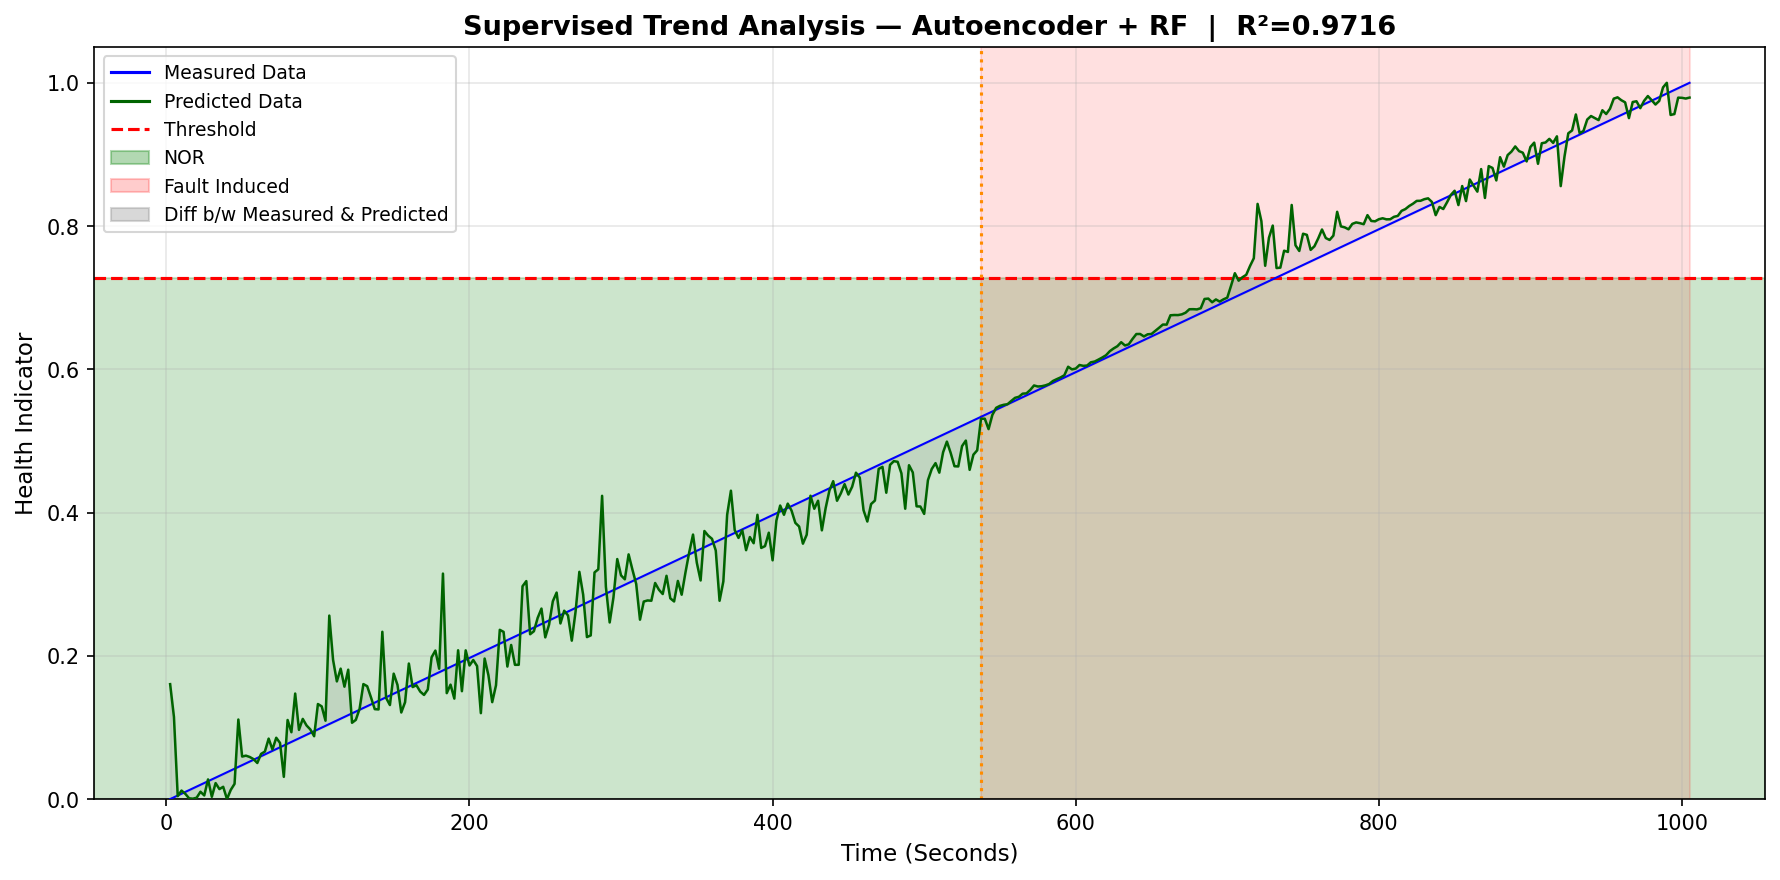

Saved: supervised_trend_plot.png  (Best model: Autoencoder + RF)


In [168]:
# ── Supervised Trend Deviation Plot ──────────────────────────────────────────
pred_norm = (pred_full_display - np.nanmin(pred_full_display))
pred_norm = pred_norm / (np.nanmax(pred_norm) + 1e-12)

# HI rises from 0 (healthy) to 1 (failure)
HI_measured  = 1 - RUL_true / (RUL_true.max() + 1e-12)
HI_predicted = 1 - pred_norm

# Threshold: 3-sigma on healthy HI
hi_healthy_region = HI_measured[:n_healthy]
hi_threshold      = float(np.clip(np.mean(hi_healthy_region) + 3*np.std(hi_healthy_region), 0, 1))

fig, ax = plt.subplots(figsize=(12, 6))

# NOR region (green band below threshold)
ax.axhspan(0, hi_threshold, alpha=0.20, color="green")

# Fault-induced zone (red shading after fault onset)
ax.axvspan(fault_onset_time, time_final[-1], alpha=0.12, color="red")

# Measured HI (blue)
ax.plot(time_final, HI_measured,  color="blue",      linewidth=1.0,
        label="Measured Data",     zorder=3)

# Predicted HI (dark green)
ax.plot(time_final, HI_predicted, color="darkgreen", linewidth=1.2,
        label="Predicted Data", zorder=4)

# Threshold dashed line
ax.axhline(hi_threshold, color="red", linestyle="--", linewidth=1.5, label="Threshold")

# Fault onset marker
ax.axvline(fault_onset_time, color="darkorange", linestyle=":", linewidth=1.5)

# Diff shading between measured and predicted
ax.fill_between(time_final, HI_measured, HI_predicted,
                alpha=0.15, color="gray", label="Diff b/w Measured & Predicted")

ax.set_title(f"Supervised Trend Analysis — {best_model_name}  |  "
             f"R²={results.iloc[0]['R²']:.4f}",
             fontsize=13, fontweight='bold')
ax.set_xlabel("Time (Seconds)", fontsize=11)
ax.set_ylabel("Health Indicator", fontsize=11)
ax.set_ylim(bottom=0)   # FIX: was set_ylim([0, None]) which errors with None

legend_elements = [
    plt.Line2D([0],[0], color='blue',      linewidth=1.5, label='Measured Data'),
    plt.Line2D([0],[0], color='darkgreen', linewidth=1.5, label='Predicted Data'),
    plt.Line2D([0],[0], color='red', linestyle='--', linewidth=1.5, label='Threshold'),
    mpatches.Patch(color='green', alpha=0.3, label='NOR'),
    mpatches.Patch(color='red',   alpha=0.2, label='Fault Induced'),
    mpatches.Patch(color='gray',  alpha=0.3, label='Diff b/w Measured & Predicted'),
]
ax.legend(handles=legend_elements, loc='upper left', fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('supervised_trend_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: supervised_trend_plot.png  (Best model: {best_model_name})")


## Combined View — Unsupervised + Supervised (Like the Figure)

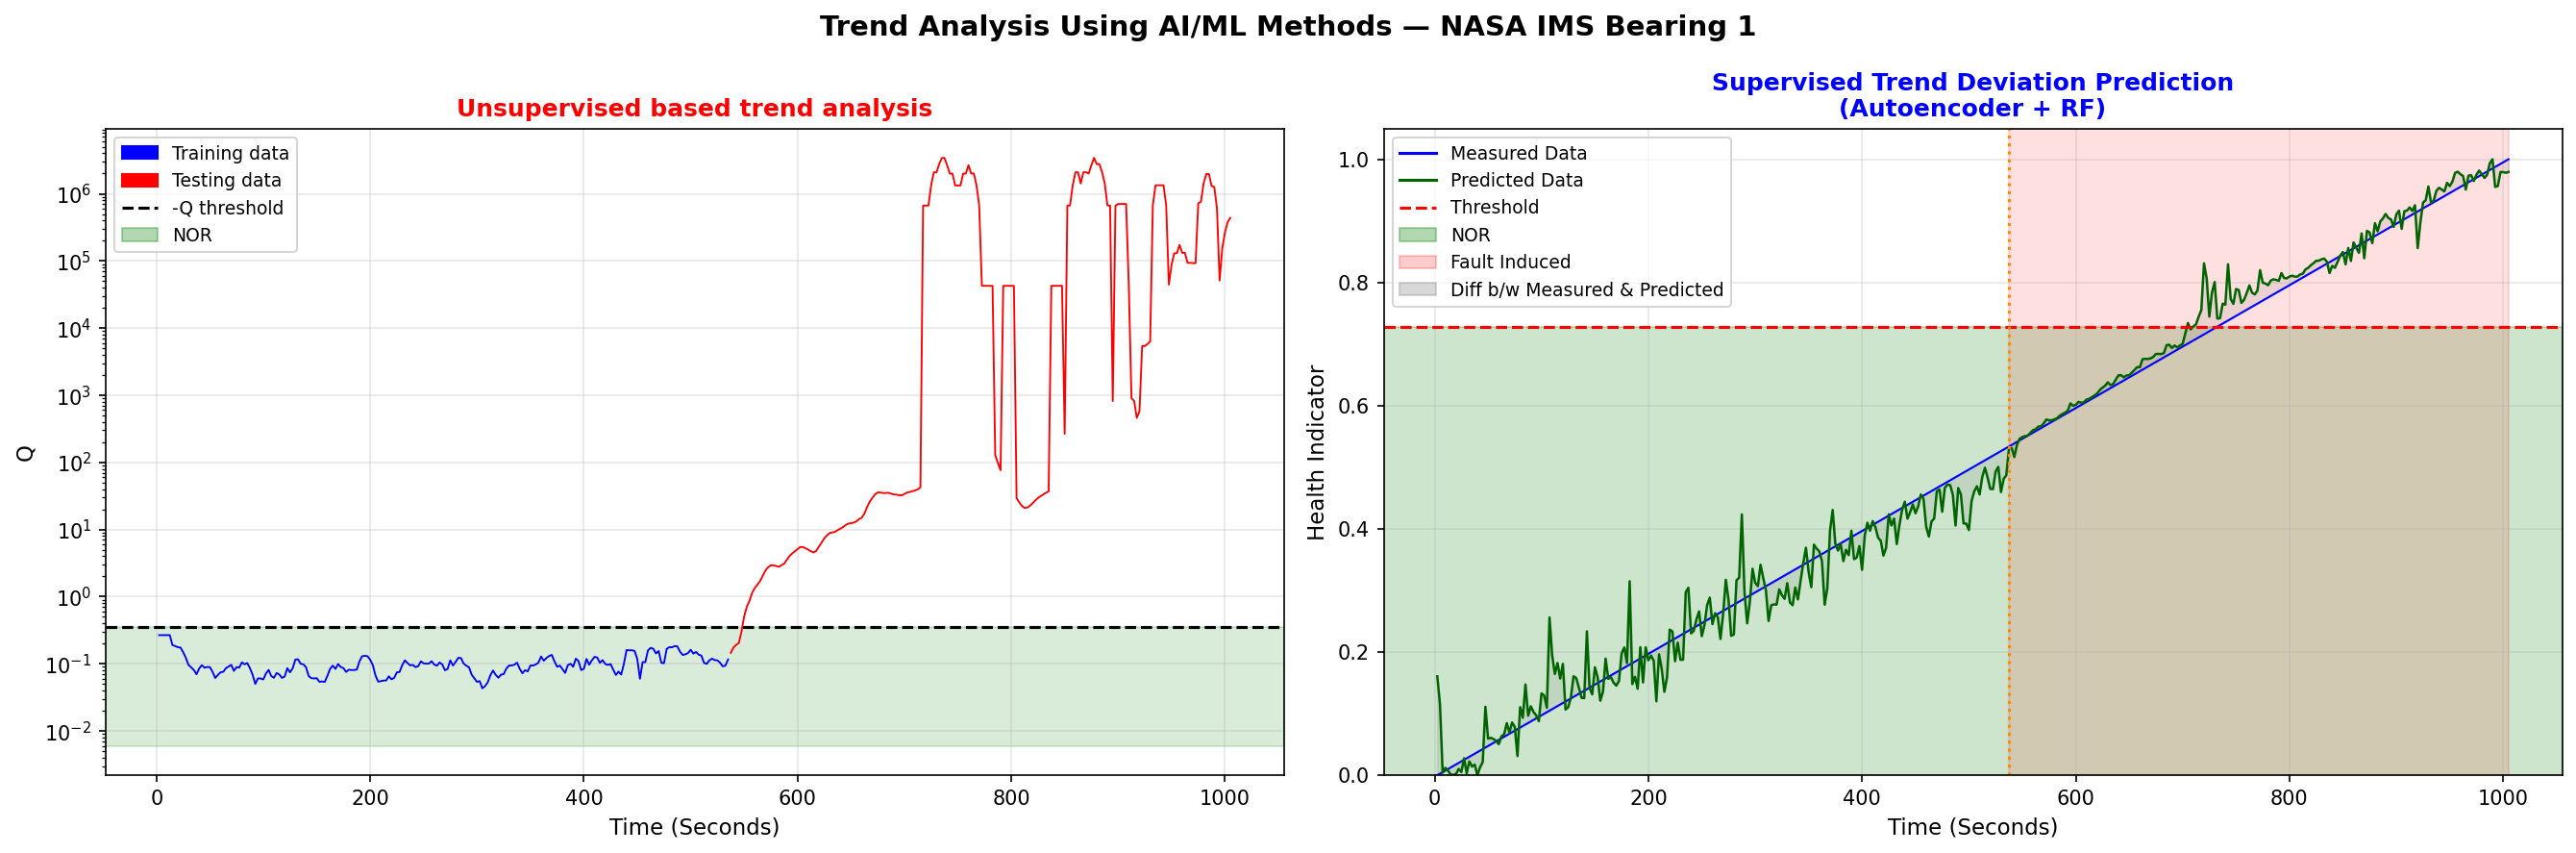

Saved: combined_trend_analysis.png


In [169]:
# ── Combined: Unsupervised (left) + Supervised (right) ───────────────────────
Q_stat_arr  = df["Q_stat"].values
Q_smooth    = pd.Series(Q_stat_arr).rolling(5).mean().bfill().values
Q_threshold = float(np.percentile(Q_stat_arr[:n_healthy], 99))

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# ── LEFT: Unsupervised Q-chart ────────────────────────────────────────────────
ax = axes[0]
ax.axhspan(float(Q_stat_arr.min()) * 0.5, Q_threshold, alpha=0.15, color="green")

# Training region (healthy) — blue
ax.semilogy(time_final[:n_healthy], Q_smooth[:n_healthy],
            color="blue", linewidth=0.9, label="Training data")

# Test region: pre-fault = blue, post-fault (and onwards) = ALL red
t_test = time_final[n_healthy:]
q_test = Q_smooth[n_healthy:]
pre    = t_test < fault_onset_time
post   = ~pre                          # from fault onset → all red, no false recoveries

if pre.any():
    ax.semilogy(t_test[pre], q_test[pre], color="blue", linewidth=0.9)
if post.any():
    ax.semilogy(t_test[post], q_test[post], color="red",  linewidth=0.9,
                label="Testing data (fault)")

ax.axhline(Q_threshold, color="black", linestyle="--", linewidth=1.5, label="-Q threshold")

patches_l = [
    mpatches.Patch(color="blue",  label="Training data"),
    mpatches.Patch(color="red",   label="Testing data"),
    plt.Line2D([0],[0], color="black", linestyle="--", label="-Q threshold"),
    mpatches.Patch(color="green", alpha=0.3, label="NOR"),
]
ax.legend(handles=patches_l, loc="upper left", fontsize=9)
ax.set_title("Unsupervised based trend analysis",
             fontsize=12, fontweight='bold', color='red')
ax.set_xlabel("Time (Seconds)"); ax.set_ylabel("Q")
ax.grid(True, alpha=0.3)

# ── RIGHT: Supervised trend ───────────────────────────────────────────────────
ax = axes[1]
ax.axhspan(0, hi_threshold, alpha=0.20, color="green")
ax.axvspan(fault_onset_time, time_final[-1], alpha=0.12, color="red")
ax.plot(time_final, HI_measured,  color="blue",      linewidth=1.0, label="Measured Data")
ax.plot(time_final, HI_predicted, color="darkgreen", linewidth=1.2, label="Predicted Data")
ax.axhline(hi_threshold, color="red",        linestyle="--", linewidth=1.5, label="Threshold")
ax.axvline(fault_onset_time, color="darkorange", linestyle=":", linewidth=1.5)
ax.fill_between(time_final, HI_measured, HI_predicted, alpha=0.15, color="gray")

patches_r = [
    plt.Line2D([0],[0], color='blue',      linewidth=1.5, label='Measured Data'),
    plt.Line2D([0],[0], color='darkgreen', linewidth=1.5, label='Predicted Data'),
    plt.Line2D([0],[0], color='red', linestyle='--', linewidth=1.5, label='Threshold'),
    mpatches.Patch(color='green', alpha=0.3, label='NOR'),
    mpatches.Patch(color='red',   alpha=0.2, label='Fault Induced'),
    mpatches.Patch(color='gray',  alpha=0.3, label='Diff b/w Measured & Predicted'),
]
ax.legend(handles=patches_r, loc='upper left', fontsize=9)
ax.set_title(f"Supervised Trend Deviation Prediction\n({best_model_name})",
             fontsize=12, fontweight='bold', color='blue')
ax.set_xlabel("Time (Seconds)"); ax.set_ylabel("Health Indicator")
ax.set_ylim(bottom=0)
ax.grid(True, alpha=0.3)

plt.suptitle("Trend Analysis Using AI/ML Methods — NASA IMS Bearing 1",
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("combined_trend_analysis.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: combined_trend_analysis.png")


## Summary Table

In [170]:
print(results.to_string(index=False))
print(f"\n  Best: {results.iloc[0]['Model']}  "
      f"R²={results.iloc[0]['R²']}  "
      f"RMSE={results.iloc[0]['RMSE (s)']}s")

            Model  MAE (s)  RMSE (s)      R²
 Autoencoder + RF     36.4      52.3  0.9716
    PCA + XGBoost     39.9      58.3  0.9647
PCA + Extra Trees     42.6      60.0  0.9626
         PCA + RF     53.9      70.1  0.9489
        KPCA + RF     52.5      70.8  0.9479
        PCA + SVR    170.4     203.5  0.5696
             LSTM    212.6     240.7 -0.5000

  Best: Autoencoder + RF  R²=0.9716  RMSE=52.3s
